# PCA — main dimensions of historical response

How many distinct features are needed to describe the observed cases?

**Real data only.** Run ingestion first. Never interpret an empty or skipped model as a finding.

In [1]:
from pathlib import Path
import sys
for loc in [Path.cwd(),Path.cwd()/'notebooks',Path.cwd()/'research_expansion'/'notebooks']:
    if (loc/'common.py').exists():
        sys.path.insert(0,str(loc.resolve()));break
from common import root, load_panel, load_cases, output

,PC1,PC2,PC3
delta_pp,0.691557,-0.141192,0.021339
shock_std_yoy,0.677734,-0.206582,0.041745
negative_share,-0.141920,-0.425718,0.796892
worst_yoy,0.173899,0.667302,0.022959
post_mean_yoy,-0.109747,-0.557549,-0.601862


Saved C:\Users\mehak\OneDrive\ドキュメント\ChatGPT\Industry Res\reports\research\models\pca.json


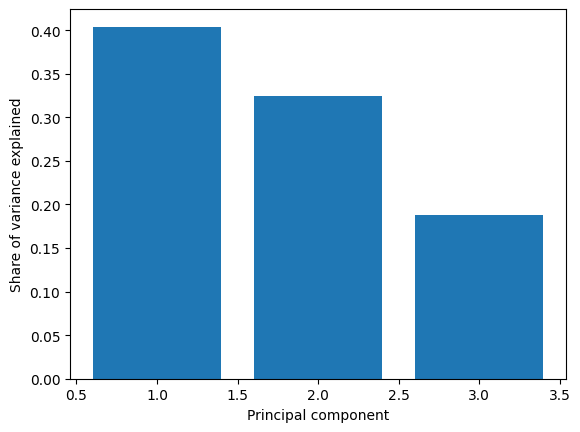

In [2]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import numpy as np, pandas as pd
df=load_cases().dropna(subset=['delta_pp','shock_std_yoy','negative_share','worst_yoy','post_mean_yoy'])
cols=['delta_pp','shock_std_yoy','negative_share','worst_yoy','post_mean_yoy']
if len(df)<8:raise ValueError('At least 8 real cases required for PCA')
X=StandardScaler().fit_transform(df[cols]);pca=PCA(n_components=min(3,len(cols),len(df)-1),random_state=42)
coords=pca.fit_transform(X)
loadings=pd.DataFrame(pca.components_.T,columns=[f'PC{k+1}' for k in range(pca.n_components_)],index=cols)
display(loadings)
output('pca',{'model':'PCA','status':'fitted','n_cases':len(df),
'explained_variance_ratio':pca.explained_variance_ratio_.tolist(),'loadings':loadings.reset_index().rename(columns={'index':'variable'}).to_dict('records'),
'limitation':'Exploratory low-sample descriptive decomposition, not evidence of causal factors.'})
import matplotlib.pyplot as plt
plt.bar(range(1,pca.n_components_+1),pca.explained_variance_ratio_)
plt.xlabel('Principal component')
plt.ylabel('Share of variance explained')
plt.show()
